In [1]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns

[*********************100%***********************]  4 of 4 completed


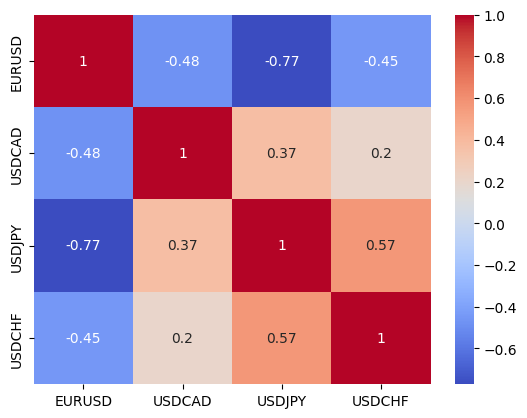

In [2]:
tickers = ["EURUSD=X", "USDCAD=X", "USDJPY=X", "USDCHF=X"]

df_prices = yf.download(tickers, period="10y")[["Close"]]
df_prices.columns = ["EURUSD", "USDCAD", "USDJPY", "USDCHF"]

df_returns = df_prices.pct_change(fill_method=None).dropna()

sns.heatmap(df_returns.corr(), annot=True, cmap="coolwarm")
plt.show()

In [6]:
X = df_returns[["USDCAD", "USDJPY"]]
Y = df_returns["EURUSD"]

X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                 EURUSD   R-squared:                       0.640
Model:                            OLS   Adj. R-squared:                  0.639
Method:                 Least Squares   F-statistic:                     2305.
Date:                Tue, 10 Mar 2026   Prob (F-statistic):               0.00
Time:                        20:10:15   Log-Likelihood:                 11633.
No. Observations:                2600   AIC:                        -2.326e+04
Df Residuals:                    2597   BIC:                        -2.324e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2.092e-05   5.41e-05     -0.386      0.6

Rsquared: 64% USDCAD and USDJPY explain the movement of EURUSD
Coef    : USDCAD 1% = EURUSD -0.24% 
        : USDJPY 1% = EURUSD -0.68% 

p-value : 0 result is real        